# **Lab 5: Neural Networks, Convolutions, and Transfer Learning**

# **Project 2: Deep Learning Applications | Individual** 

**Student Name: Muhammad Bilal**

**Semester: BS 7th Semester**

**Department: Department of Electronics**

**Course: Introduction to Applied AI**

# Part 1: The Data, and an Image as Numbers
**Task 1.1: Imports, GPU check, and class counts**

In [1]:
import os
import time
import copy
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms, models
from sklearn.metrics import (classification_report, confusion_matrix,
                             ConfusionMatrixDisplay)
torch.manual_seed(42)
np.random.seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)   # must say cuda; if not, turn on the GPU
ROOT = '/kaggle/input/datasets/puneet6060/intel-image-classification'
TRAIN_DIR = f'{ROOT}/seg_train/seg_train'
TEST_DIR = f'{ROOT}/seg_test/seg_test'
classes = sorted(os.listdir(TRAIN_DIR))
for c in classes:
    n_tr = len(os.listdir(os.path.join(TRAIN_DIR, c)))
    n_te = len(os.listdir(os.path.join(TEST_DIR, c)))
    print(f'{c:10s} train {n_tr:5d}   test {n_te:4d}')

Device: cuda
buildings  train  2191   test  437
forest     train  2271   test  474
glacier    train  2404   test  553
mountain   train  2512   test  525
sea        train  2274   test  510
street     train  2382   test  501


**Task 1.2: Look at the images, then at the numbers**

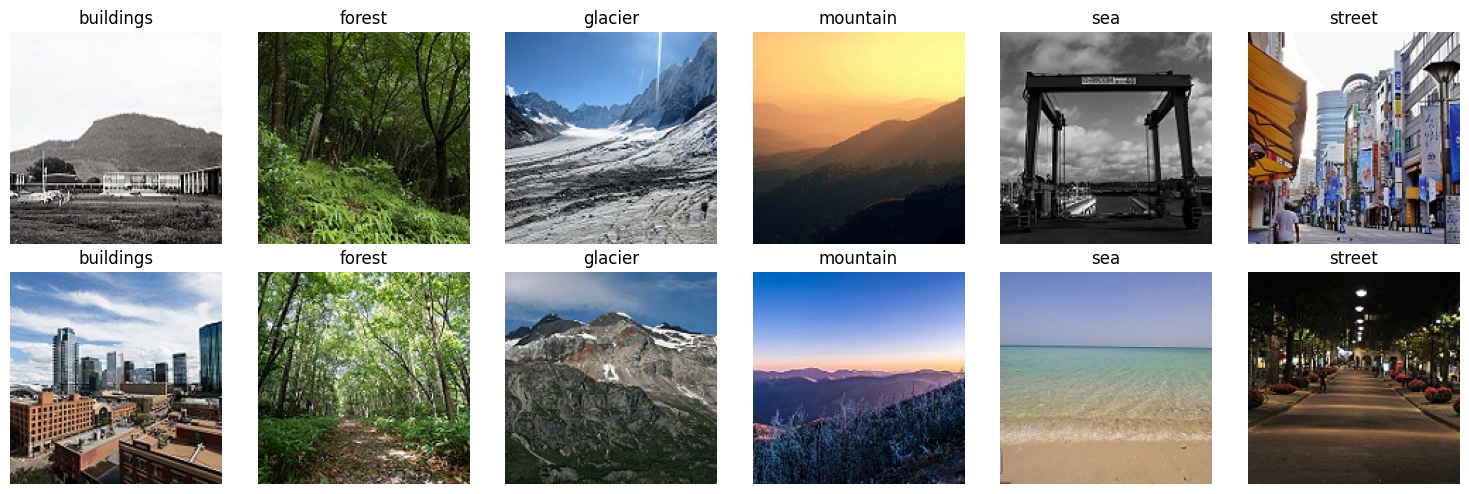

Shape (H, W, C): (150, 150, 3)  dtype: uint8  range: 0 to 255
Top-left 3x3 of the red channel:
 [[8 6 3]
 [6 5 4]
 [5 5 5]]


In [2]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for j, c in enumerate(classes):
    files = sorted(os.listdir(os.path.join(TRAIN_DIR, c)))[:2]
    for i, f in enumerate(files):
        img = Image.open(os.path.join(TRAIN_DIR, c, f))
        axes[i, j].imshow(img)
        axes[i, j].set_title(c)
        axes[i, j].axis('off')
plt.tight_layout()
plt.show()
arr = np.array(img)
print('Shape (H, W, C):', arr.shape, ' dtype:', arr.dtype,
      ' range:', arr.min(), 'to', arr.max())
print('Top-left 3x3 of the red channel:\n', arr[:3, :3, 0])

# Part 2: Convolution and Parameters by Hand 
**Task 2.1: Reproduce the lecture's convolution**

tensor([[30., 30.,  0.],
        [30., 30.,  0.],
        [30., 30.,  0.]])


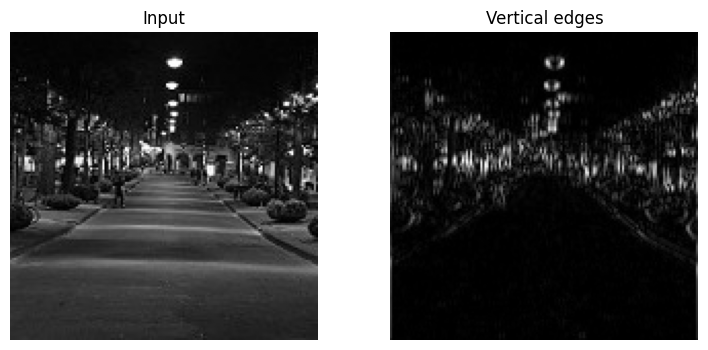

In [3]:
# The 5x5 example from the lecture: a vertical edge
x = torch.tensor([[0, 0, 10, 10, 10]] * 5, dtype=torch.float32)
k = torch.tensor([[-1, 0, 1]] * 3, dtype=torch.float32)
out = F.conv2d(x.view(1, 1, 5, 5), k.view(1, 1, 3, 3))
print(out.squeeze())            # expect three rows of [30, 30, 0]
# The same kernel on a real photo, converted to grayscale
g = transforms.functional.to_tensor(img.convert('L')).unsqueeze(0)
edges = F.conv2d(g, k.view(1, 1, 3, 3), padding=1)
fig, ax = plt.subplots(1, 2, figsize=(9, 4))
ax[0].imshow(g.squeeze(), cmap='gray')
ax[0].set_title('Input')
ax[1].imshow(edges.squeeze().abs(), cmap='gray')
ax[1].set_title('Vertical edges')
for a in ax:
    a.axis('off')
plt.show()

**Task 2.2: Why convolutions, in numbers**

In [4]:
def count(m):
    return sum(p.numel() for p in m.parameters())
conv = nn.Conv2d(in_channels=3, out_channels=64, kernel_size=3, padding=1)
dense = nn.Linear(150 * 150 * 3, 512)
print(f'Conv 3x3, 3 -> 64   : {count(conv):,} parameters')  # (3*3*3+1)*64
print(f'Dense 67,500 -> 512 : {count(dense):,} parameters')
t = torch.randn(1, 3, 224, 224)
for stride in [1, 2]:
    c = nn.Conv2d(3, 64, kernel_size=3, stride=stride, padding=1)
    print(f'stride {stride}: output {tuple(c(t).shape)}')  # (W-K+2P)/S + 1
print('2x2 max pool:', tuple(F.max_pool2d(t, 2).shape))

Conv 3x3, 3 -> 64   : 1,792 parameters
Dense 67,500 -> 512 : 34,560,512 parameters
stride 1: output (1, 64, 224, 224)
stride 2: output (1, 64, 112, 112)
2x2 max pool: (1, 3, 112, 112)


# Part 3: Transforms and Data Loaders 

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]  # ImageNet stats
train_tf = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.7, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
# Two views of the same folder: augmented for training, clean for validation
full_aug = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
idx = np.random.permutation(len(full_aug))
n_val = int(0.15 * len(idx))
train_ds = Subset(full_aug, idx[n_val:])
val_ds = Subset(full_eval, idx[:n_val])
test_ds = datasets.ImageFolder(TEST_DIR, transform=eval_tf)
train_dl = DataLoader(train_ds, batch_size=64, shuffle=True, num_workers=2)
val_dl = DataLoader(val_ds, batch_size=128, num_workers=2)
test_dl = DataLoader(test_ds, batch_size=128, num_workers=2)
print(len(train_ds), 'train |', len(val_ds), 'val |', len(test_ds), 'test')

11929 train | 2105 val | 3000 test


# Part 4: The Training Loop and Feature Extraction 
**Task 4.1: A reusable training loop**

In [6]:
def run_epoch(model, loader, optimizer=None):
    """One pass over the data. Trains only if an optimizer is given."""
    training = optimizer is not None
    model.train(training)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)                     # forward pass
            loss = F.cross_entropy(logits, yb)     # softmax + log loss
            if training:
                optimizer.zero_grad()
                loss.backward()                    # backpropagation
                optimizer.step()                   # gradient step
            total_loss += loss.item() * len(yb)
            correct += (logits.argmax(1) == yb).sum().item()
            n += len(yb)
    return total_loss / n, correct / n
def fit(model, optimizer, epochs, history):
    best_acc, best_state = -1.0, None
    for ep in range(epochs):
        t0 = time.time()
        tr_loss, tr_acc = run_epoch(model, train_dl, optimizer)
        va_loss, va_acc = run_epoch(model, val_dl)
        history.append((tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_acc:
            best_acc = va_acc
            best_state = copy.deepcopy(model.state_dict())
        print(f'epoch {ep + 1}: train loss {tr_loss:.3f} acc {tr_acc:.3f} | '
              f'val loss {va_loss:.3f} acc {va_acc:.3f} '
              f'({time.time() - t0:.0f}s)')
    model.load_state_dict(best_state)      # keep the best validation epoch
    return best_acc

**Task 4.2: Freeze the body, train a new head**

In [7]:
model = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
for p in model.parameters():
    p.requires_grad = False                           # freeze the body
model.fc = nn.Linear(model.fc.in_features, len(classes))  # new 6-class head
model = model.to(device)
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable {trainable:,} of {count(model):,} parameters')
history = []
opt = torch.optim.Adam(model.fc.parameters(), lr=1e-3)
best = fit(model, opt, epochs=3, history=history)
print(f'Best validation accuracy, feature extraction: {best:.3f}')

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 223MB/s]


Trainable 3,078 of 11,179,590 parameters
epoch 1: train loss 0.588 acc 0.809 | val loss 0.327 acc 0.894 (78s)
epoch 2: train loss 0.326 acc 0.890 | val loss 0.290 acc 0.899 (37s)
epoch 3: train loss 0.299 acc 0.895 | val loss 0.276 acc 0.901 (38s)
Best validation accuracy, feature extraction: 0.901


# Part 5: Fine-Tuning and Learning Curves 
**Task 5.1: Unfreeze layer4 with a smaller learning rate**

In [17]:
# --- Part 5: Task 5.1 ---

# 1. Unfreeze the last block of the pretrained body (layer4)
for p in model.layer4.parameters():
    p.requires_grad = True

# 2. Set up the optimizer with discriminative learning rates
# 'params' key groups the parameters, and each group gets its own 'lr'.
opt = torch.optim.Adam([
    {'params': model.layer4.parameters(), 'lr': 1e-4}, # Gentle learning rate for pretrained weights
    {'params': model.fc.parameters(), 'lr': 1e-3}    # Faster learning rate for the new head
])

# 3. Print the number of parameters we are now training
# Notice how this number jumps.
trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Trainable parameters now: {trainable:,}') # Should be about 8.4 million

# 4. Train for another 3 epochs (appending to the same history)
print("\nStarting fine-tuning...")
best = fit(model, opt, epochs=3, history=history)

# The fit() function reloads the overall best weights.
print(f'\nBest validation accuracy after all training (feature extraction + fine-tuned): {best:.3f}')

Trainable parameters now: 8,396,806

Starting fine-tuning...
epoch 1: train loss 0.095 acc 0.965 | val loss 0.232 acc 0.934 (38s)
epoch 2: train loss 0.067 acc 0.975 | val loss 0.298 acc 0.922 (37s)
epoch 3: train loss 0.057 acc 0.980 | val loss 0.298 acc 0.932 (37s)

Best validation accuracy after all training (feature extraction + fine-tuned): 0.934


**Task 5.2: Plot the learning curves**

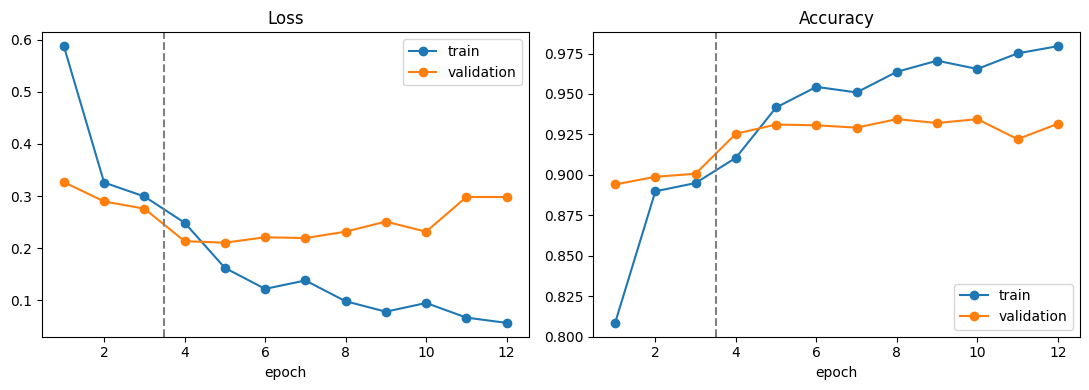

In [18]:
# --- Part 5: Task 5.2 ---

# 1. Convert the list of tuples (history) into a NumPy array for easier slicing
h = np.array(history)

# 2. Create an array for the x-axis (epochs) from 1 to 6 (3 + 3)
ep = np.arange(1, len(h) + 1)

# 3. Create a figure with two subplots: one for Loss and one for Accuracy
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

# --- Plot Loss (tr_loss vs val_loss) ---
ax[0].plot(ep, h[:, 0], 'o-', label='train')      # tr_loss is index 0
ax[0].plot(ep, h[:, 1], 'o-', label='validation') # val_loss is index 1

# --- Plot Accuracy (tr_acc vs val_acc) ---
ax[1].plot(ep, h[:, 2], 'o-', label='train')      # tr_acc is index 2
ax[1].plot(ep, h[:, 3], 'o-', label='validation') # val_acc is index 3

# 4. Add labels, titles, and a marker for when fine-tuning started
for a, title in zip(ax, ['Loss', 'Accuracy']):
    # Add a dashed vertical line after epoch 3 to mark the phase change
    a.axvline(3.5, color='gray', ls='--') 
    a.set_title(title)
    a.set_xlabel('epoch')
    a.legend()

plt.tight_layout()
plt.show()

# Part 6: Test Once, Then Study the Errors 
**Task 6.1: Test-set evaluatio**

Evaluating on test set...

TEST ACCURACY (the final report): 0.936

Classification Report:

              precision    recall  f1-score   support

   buildings      0.926     0.947     0.937       437
      forest      0.998     0.992     0.995       474
     glacier      0.891     0.884     0.887       553
    mountain      0.901     0.888     0.894       525
         sea      0.949     0.986     0.967       510
      street      0.957     0.928     0.942       501

    accuracy                          0.936      3000
   macro avg      0.937     0.938     0.937      3000
weighted avg      0.936     0.936     0.936      3000



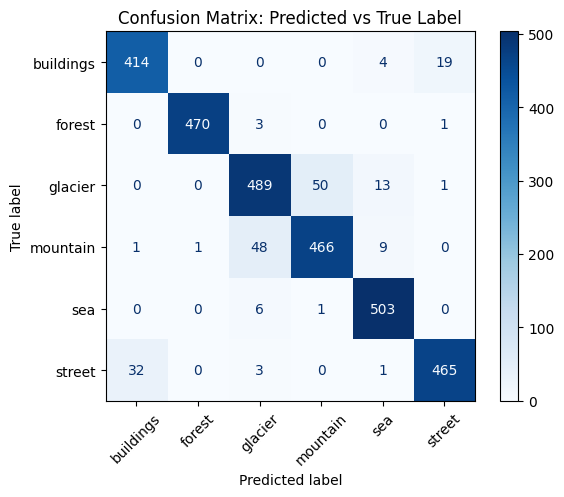

In [19]:
# --- Part 6: Task 6.1 ---

# 1. Prepare for evaluation
model.eval() # CRITICAL: sets model behavior correctly for eval
probs, preds, labels = [], [], []

print("Evaluating on test set...")
with torch.no_grad(): # Disable gradients to save memory and computation
    for xb, yb in test_dl:
        # 1. Forward pass on the batch
        output = model(xb.to(device))
        
        # 2. Get probabilities using softmax
        p = F.softmax(output, dim=1).cpu() # Move output to CPU
        
        # 3. Store results
        probs.append(p)
        preds.append(p.argmax(1)) # Get the index of the highest prob
        labels.append(yb)         # yb are already integers on CPU

# Concatenate all batches of results into single tensors
probs = torch.cat(probs)
preds = torch.cat(preds)
labels = torch.cat(labels)

# 2. Print final test accuracy
print(f'\nTEST ACCURACY (the final report): {(preds == labels).float().mean():.3f}')

# 3. Print the detailed classification report
print("\nClassification Report:\n")
print(classification_report(labels, preds, target_names=classes, digits=3))

# 4. Compute and display the confusion matrix
cm = confusion_matrix(labels, preds)
disp = ConfusionMatrixDisplay(cm, display_labels=classes)
disp.plot(cmap='Blues', xticks_rotation=45)
plt.title('Confusion Matrix: Predicted vs True Label')
plt.show()

**Task 6.2: Error gallery**

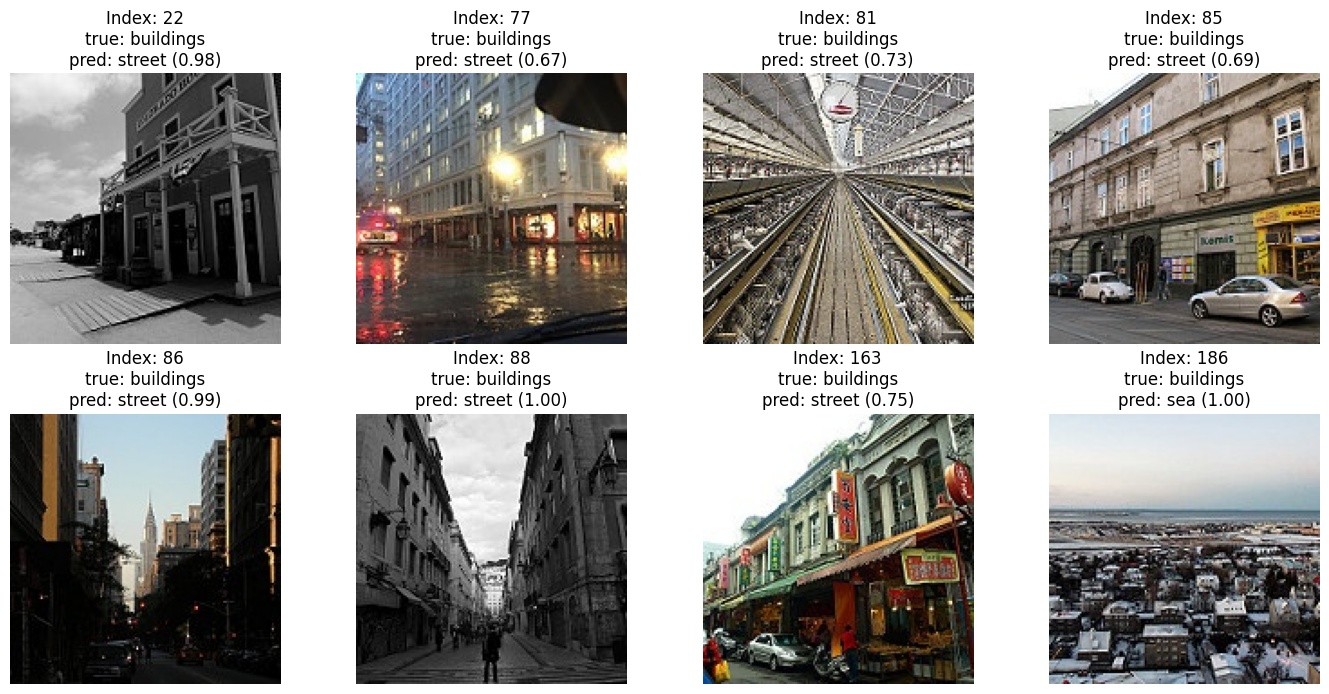

In [21]:
# --- Part 6: Task 6.2 ---

# 1. Find the indices of all misclassified images
wrong = torch.where(preds != labels)[0] # Get indices where pred != true label
# To keep it manageable, we'll only look at the first 8 errors found.
indices_to_show = wrong[:8]

# 2. Create a 2x4 plot grid
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
# Turn off axes for all subplots initially
for ax in axes.flat:
    ax.axis('off')

# 3. Loop through the error indices and populate the grid
# Zip pairs each axis with one of the first 8 wrong indices.
for ax, i in zip(axes.flat, indices_to_show.tolist()):
    
    # We need the original, un-transformed image file to display.
    # test_ds.samples[i] returns (filepath, label_integer) for the i-th item.
    path, _ = test_ds.samples[i]
    img = Image.open(path)
    ax.imshow(img)
    
    # Create the title with detailed information
    # f'true: {classes[labels[i]]}\n' -> true: buildings
    # f'pred: {classes[preds[i]]} ({probs[i].max():.2f})' -> pred: street (0.87)
    title_text = (f'Index: {i}\n'
                  f'true: {classes[labels[i]]}\n'
                  f'pred: {classes[preds[i]]} ({probs[i].max():.2f})')
    
    ax.set_title(title_text)

plt.tight_layout()
plt.show()

**Task 6.3: Inside one prediction**

In [22]:
x0, y0 = test_ds[0]
with torch.no_grad():
    logits = model(x0.unsqueeze(0).to(device)).cpu().squeeze()
p = F.softmax(logits, dim=0)
print('True class:', classes[y0])
for c, z, q in zip(classes, logits.tolist(), p.tolist()):
    print(f'{c:10s} logit {z:6.2f}   probability {q:.3f}')

True class: buildings
buildings  logit  10.15   probability 1.000
forest     logit  -9.32   probability 0.000
glacier    logit  -6.17   probability 0.000
mountain   logit  -7.01   probability 0.000
sea        logit  -7.23   probability 0.000
street     logit  -4.73   probability 0.000


**Part 7: Save and Share**

In [23]:
path = '/kaggle/working/resnet18_intel.pt'
torch.save(model.state_dict(), path)
print(f'Saved {path} ({os.path.getsize(path) / 1e6:.1f} MB)')

Saved /kaggle/working/resnet18_intel.pt (44.8 MB)
